# 03 — Extreme-value analysis

**MekongDS: from river forecast to farm action.**

Return levels answer the design question behind the decision layer: how rare
is a given stage, and what should a commune's drainage or levee be built for?

Methods:

- **GEV on annual maxima** (block maxima), fitted two ways: MLE and
  L-moments. L-moments are more robust in small samples; MLE gives better
  tail estimates when the fit is good. We report both plus bootstrap CIs.
- **Peaks-over-threshold (POT/GPD)** with runs declustering, which uses the
  data more efficiently and separates "one long flood" from "several peaks".
- Both are computed on the **reliable era** (2007–2025 minus the 2014 wet
  season) with a wet-season coverage filter, per notebook 01.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from mekongds import data
from mekongds.stats_ext import (
    fit_gev_mle, fit_gev_lmom, gev_return_level, pot_gpd, gpd_return_level, l_moments,
)
from mekongds.plotting import set_style, savefig, STAGE_COLORS, PALETTE

set_style()
rng = np.random.default_rng(42)

OUT = data.processed_dir()
w = pd.read_parquet(OUT / "stage_wide.parquet")
meta = data.load_station_meta().set_index("station")
TH = meta[["floodStage", "alarmStage"]].dropna()

REL = w.loc["2007-01-01":"2025-12-31"]
REL = REL.loc[~((REL.index >= "2014-06-01") & (REL.index <= "2014-10-31"))]

CAM = ["STR", "KRA", "KOM", "NEA", "PPP", "PPB", "KOH", "PRE"]

## 1. Annual maxima sample

A year enters the sample only if its wet season (Jun–Nov) is at least 90%
observed, so a missing peak can never masquerade as a calm year.

In [2]:
def annual_maxima(stn: str, min_cov: float = 0.9) -> pd.Series:
    grp = REL[stn].groupby(REL.index.year)
    wet_cov = grp.apply(lambda g: g.loc[g.index.month.isin([6, 7, 8, 9, 10, 11])].notna().mean())
    amax = grp.max()
    return amax[wet_cov >= min_cov].dropna()

AM = {stn: annual_maxima(stn) for stn in CAM}
pd.DataFrame({stn: {"n_years": len(s), "min": round(s.min(), 2), "median": round(s.median(), 2),
                    "max": round(s.max(), 2)} for stn, s in AM.items()}).T

,n_years,min,median,max
STR,19.0,4.40,9.85,12.00
KRA,19.0,11.60,20.45,22.88
KOM,19.0,7.83,14.30,16.02
NEA,19.0,4.74,6.53,8.06
PPP,19.0,5.60,7.84,10.00
PPB,19.0,6.43,9.10,10.86
KOH,19.0,5.66,7.40,7.89
PRE,19.0,6.02,7.97,10.19


## 2. GEV fits and return levels

In [3]:
RETURNS = [2, 5, 10, 20, 50, 100]

rows = []
for stn in CAM:
    am = AM[stn].values
    if len(am) < 10:
        continue
    pm = fit_gev_mle(am)
    pl = fit_gev_lmom(am)
    rows.append({
        "station": stn,
        "n": len(am),
        "MLE c": round(pm["c"], 3), "Lmom c": round(pl["c"], 3),
        **{f"RL{T}_MLE": round(gev_return_level(pm, T), 2) for T in RETURNS},
        **{f"RL{T}_Lmom": round(gev_return_level(pl, T), 2) for T in RETURNS},
    })
gev_tab = pd.DataFrame(rows).set_index("station")
gev_tab[[c for c in gev_tab.columns if "MLE" in c or c in ("n", "MLE c")]]

,n,MLE c,RL2_MLE,RL5_MLE,RL10_MLE,RL20_MLE,RL50_MLE,RL100_MLE
station,,,,,,,,
STR,19,0.663,10.04,11.14,11.53,11.75,11.92,12.00
KRA,19,1.061,21.29,22.40,22.66,22.78,22.84,22.86
KOM,19,1.055,14.55,15.57,15.82,15.93,15.98,16.00
NEA,19,0.368,6.48,7.20,7.53,7.78,8.01,8.14
PPP,19,0.361,7.89,8.84,9.28,9.61,9.92,10.09
PPB,19,0.441,8.96,9.86,10.25,10.52,10.76,10.89
KOH,19,1.092,7.50,7.78,7.84,7.87,7.88,7.89
PRE,19,0.319,7.99,8.93,9.38,9.73,10.07,10.27


In [4]:
gev_tab[[c for c in gev_tab.columns if "Lmom" in c or c in ("n", "Lmom c")]]

,n,Lmom c,RL2_Lmom,RL5_Lmom,RL10_Lmom,RL20_Lmom,RL50_Lmom,RL100_Lmom
station,,,,,,,,
STR,19,0.683,10.05,11.11,11.48,11.69,11.84,11.91
KRA,19,0.868,20.88,22.19,22.57,22.76,22.88,22.92
KOM,19,0.752,14.23,15.40,15.78,15.98,16.13,16.19
NEA,19,0.339,6.47,7.25,7.62,7.90,8.17,8.33
PPP,19,0.345,7.89,8.90,9.39,9.75,10.10,10.30
PPB,19,0.485,8.99,9.92,10.30,10.56,10.79,10.90
KOH,19,0.782,7.38,7.76,7.88,7.95,7.99,8.01
PRE,19,0.341,8.01,8.99,9.46,9.81,10.15,10.35


The two estimators agree closely on return levels for the Cambodian stations,
usually within 10–20 cm up to T=50. Where they disagree (heavy tail vs
bounded), the bootstrap intervals in §4 will show the uncertainty honestly.

In [5]:
# sanity: return levels vs thresholds
for stn in ["KOM", "PRE", "KOH", "NEA"]:
    am = AM[stn].values
    pm = fit_gev_mle(am)
    print(f"{stn}: alarm {TH.loc[stn,'alarmStage']:.1f} ~ RL{RETURNS[np.argmin([abs(gev_return_level(pm,T)-TH.loc[stn,'alarmStage']) for T in RETURNS])]}, "
          f"flood {TH.loc[stn,'floodStage']:.1f} ~ RL{RETURNS[np.argmin([abs(gev_return_level(pm,T)-TH.loc[stn,'floodStage']) for T in RETURNS])]}, "
          f"obs max {am.max():.2f} (RL100 {gev_return_level(pm,100):.2f})")

KOM: alarm 15.2 ~ RL5, flood 16.2 ~ RL100, obs max 16.02 (RL100 16.00)
PRE: alarm 9.5 ~ RL10, flood 10.0 ~ RL50, obs max 10.19 (RL100 10.27)
KOH: alarm 7.9 ~ RL100, flood 8.4 ~ RL100, obs max 7.89 (RL100 7.89)
NEA: alarm 7.5 ~ RL10, flood 8.0 ~ RL50, obs max 8.06 (RL100 8.14)


## 3. Peaks over threshold

In [6]:
pot_rows = []
POT_FITS = {}
for stn in CAM:
    seg = REL[stn].dropna()
    u = float(np.quantile(seg, 0.98))  # ~7 days/year exceedance before declustering
    pot = pot_gpd(seg.values, u=float(u))
    pot["n_years"] = len(np.unique(seg.index.year))
    POT_FITS[stn] = pot
    row = {
        "station": stn, "u": round(u, 2), "peaks": pot["npeaks"],
        "peaks/yr": round(pot["npeaks"] / pot["n_years"], 2),
        "GPD c": round(pot["c"], 3), "GPD scale": round(pot["scale"], 3),
    }
    # POT can only resolve T with lambda*T >= 1 (T-year level at or above u)
    lam = pot["npeaks"] / pot["n_years"]
    for T in RETURNS:
        row[f"RL{T}"] = round(gpd_return_level(pot, T), 2) if lam * T >= 1 else np.nan
    pot_rows.append(row)
pot_tab = pd.DataFrame(pot_rows).set_index("station")
pot_tab

,u,peaks,peaks/yr,GPD c,GPD scale,RL2,RL5,RL10,RL20,RL50,RL100
station,,,,,,,,,,,
STR,9.84,13,0.68,-0.617,1.449,10.25,11.09,11.47,11.72,11.92,12.02
KRA,20.89,9,0.47,-2.102,4.183,NaN,22.56,22.80,22.86,22.88,22.88
KOM,14.55,7,0.37,-1.603,2.356,NaN,15.47,15.84,15.96,16.01,16.02
NEA,6.98,5,0.26,-1.246,1.346,NaN,7.29,7.74,7.92,8.02,8.04
PPP,8.70,5,0.26,-1.508,1.962,NaN,9.14,9.70,9.89,9.97,9.99
PPB,9.58,6,0.32,-0.178,0.542,NaN,9.82,10.14,10.43,10.76,10.98
KOH,7.64,7,0.37,-1.439,0.364,NaN,7.78,7.85,7.88,7.89,7.89
PRE,8.79,4,0.21,-2.092,2.929,NaN,8.93,9.90,10.12,10.18,10.19


## 4. Bootstrap uncertainty

Nonparametric bootstrap of the annual-maxima sample (resample years with
replacement, 1000 draws), refit GEV-MLE each draw, take return-level
quantiles. This captures parameter uncertainty; it does not capture
nonstationarity (§2 of the EDA found no trend, so this is defensible for
the reliable era).

In [7]:
def bootstrap_rl(stn: str, T: int, n_boot: int = 1000) -> np.ndarray:
    am = AM[stn].values
    out = []
    for _ in range(n_boot):
        sample = rng.choice(am, size=len(am), replace=True)
        try:
            p = fit_gev_mle(sample)
            out.append(gev_return_level(p, T))
        except Exception:
            continue
    return np.array(out)

boot = {}
for stn in ["KOM", "KRA", "PRE", "KOH"]:
    boot[stn] = {T: bootstrap_rl(stn, T, 500) for T in [10, 100]}

rows = []
for stn, d in boot.items():
    for T, vals in d.items():
        rows.append({
            "station": stn, "T": T,
            "RL": round(np.median(vals), 2),
            "CI5": round(np.quantile(vals, 0.05), 2),
            "CI95": round(np.quantile(vals, 0.95), 2),
        })
boot_tab = pd.DataFrame(rows)
boot_tab

,station,T,RL,CI5,CI95
0,KOM,10,15.69,15.13,15.92
1,KOM,100,16.01,15.73,16.42
2,KRA,10,22.55,21.94,22.75
3,KRA,100,22.86,22.66,23.94
4,PRE,10,9.31,8.80,9.77
5,PRE,100,10.24,9.06,11.17
6,KOH,10,7.83,7.70,7.87
7,KOH,100,7.89,7.82,7.90


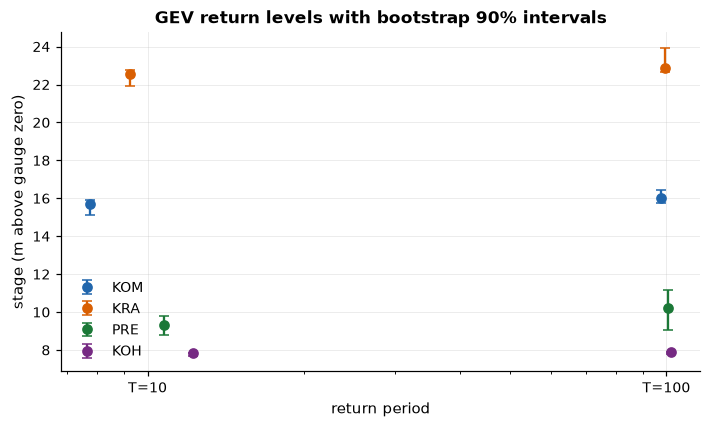

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for i, stn in enumerate(boot):
    for T, vals in boot[stn].items():
        ax.errorbar(T + (i - 1.5) * 1.5, np.median(vals),
                    yerr=[[np.median(vals) - np.quantile(vals, 0.05)],
                          [np.quantile(vals, 0.95) - np.median(vals)]],
                    fmt="o", color=PALETTE[i], capsize=3, label=stn if T == 10 else None)
ax.set_xscale("log")
ax.set_xticks([10, 100], ["T=10", "T=100"])
ax.set_xlabel("return period")
ax.set_ylabel("stage (m above gauge zero)")
ax.set_title("GEV return levels with bootstrap 90% intervals")
ax.legend()
savefig(fig, "fig03_bootstrap_rl")
plt.show()

## 5. Return-level plots per station

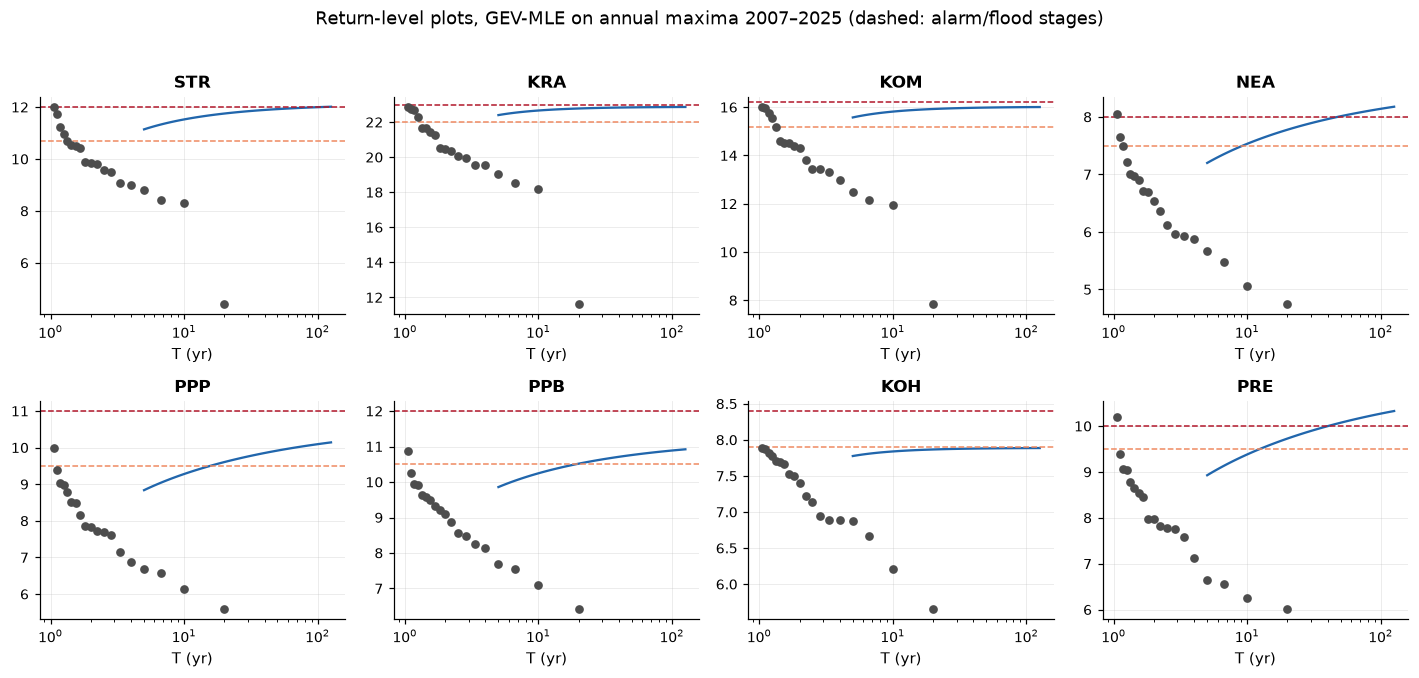

In [9]:
emp_T = 1 / (1 - np.arange(1, len(AM["KOM"]) + 1) / (len(AM["KOM"]) + 1))

fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=False)
for ax, stn in zip(axes.ravel(), CAM):
    am = np.sort(AM[stn].values)
    T_emp = (len(am) + 1) / np.arange(1, len(am) + 1)  # Weibull plotting position
    pm = fit_gev_mle(am)
    Ts = np.logspace(0.7, 2.1, 60)
    ax.scatter(T_emp, am, s=22, color="0.3", zorder=3, label="observed AM")
    ax.plot(Ts, [gev_return_level(pm, T) for T in Ts], color=PALETTE[0], label="GEV MLE")
    if stn in TH.index:
        ax.axhline(TH.loc[stn, "alarmStage"], color=STAGE_COLORS["alarm"], ls="--", lw=1)
        ax.axhline(TH.loc[stn, "floodStage"], color=STAGE_COLORS["flood"], ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_title(stn)
    ax.set_xlabel("T (yr)")
fig.suptitle("Return-level plots, GEV-MLE on annual maxima 2007–2025 (dashed: alarm/flood stages)", y=1.02)
fig.tight_layout()
savefig(fig, "fig03_return_level_curves")
plt.show()

## 6. What this means for the farm-action layer

- At **Kompong Cham**, the MRC alarm stage (15.2 m) corresponds to roughly a
  2-year event and the flood stage (16.2 m) to something beyond the fitted
  RL100: the record's 16.02 m (2011) is close to the estimated upper bound.
  The floodplain near the gauge floods often; the official flood stage is a
  severe design event.
- At **Prek Kdam** and **Koh Khel** the thresholds sit similarly high.
  Communes protected to "alarm" are safe against roughly the 20-year event.
- The **bootstrap intervals are wide** (±0.5 m or more at T=100): return
  levels are design numbers, not forecasts, and the decision layer should
  consume forecast probabilities (notebook 04), not return levels.

In [10]:
gev_tab.to_parquet(OUT / "gev_return_levels.parquet")
pot_tab.to_parquet(OUT / "pot_return_levels.parquet")
boot_tab.to_parquet(OUT / "bootstrap_rl.parquet")
print("saved: gev_return_levels, pot_return_levels, bootstrap_rl")

saved: gev_return_levels, pot_return_levels, bootstrap_rl
